In [102]:
import pandas as pd
import kagglehub

path = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")
df = pd.read_csv(f"{path}/Car details v3.csv")

In [103]:
import numpy as np

def filter_outliers(dframe, column):
    Q1 = dframe[column].quantile(0.25)
    Q3 = dframe[column].quantile(0.75)
    IQR = Q3 - Q1
    return dframe[~((dframe[column] < (Q1 - 1.5 * IQR)) | (dframe[column] > (Q3 + 1.5 * IQR)))]
    
df = df.drop_duplicates()

df['car_age'] = 2026 - df['year']

df = df[df['mileage'].str.split().str[-1] == "kmpl"]
df['mileage'] = df['mileage'].str.split().str[0].astype(float)
df['engine'] = df['engine'].str.split().str[0].astype(float)
df['max_power'] = df['max_power'].str.split().str[0].astype(float)
df['mileage'] = df['mileage'].replace(0, np.nan)

df = filter_outliers(df, 'km_driven')

df = df.drop(columns=["name", "year", "torque"]).reset_index().drop(columns=["index"])

In [104]:
df.head()

,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,car_age
0,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,12
1,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,12
2,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,20
3,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,16
4,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,19


In [105]:
df["max_power"].describe()

count    6474.000000
mean       87.976351
std        31.818567
min        34.200000
25%        68.000000
50%        81.860000
75%        99.600000
max       400.000000
Name: max_power, dtype: float64

In [106]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6474 entries, 0 to 6473
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   selling_price  6474 non-null   int64  
 1   km_driven      6474 non-null   int64  
 2   fuel           6474 non-null   str    
 3   seller_type    6474 non-null   str    
 4   transmission   6474 non-null   str    
 5   owner          6474 non-null   str    
 6   mileage        6459 non-null   float64
 7   engine         6474 non-null   float64
 8   max_power      6474 non-null   float64
 9   seats          6474 non-null   float64
 10  car_age        6474 non-null   int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 556.5 KB


In [107]:
df.describe()

,selling_price,km_driven,mileage,engine,max_power,seats,car_age
count,6.474000e+03,6474.000000,6459.000000,6474.000000,6474.000000,6474.000000,6474.000000
mean,5.324786e+05,68666.903151,19.569678,1421.995984,87.976351,5.413500,12.300741
std,5.306877e+05,39836.853614,3.868517,484.097157,31.818567,0.960365,3.876222
min,2.999900e+04,1000.000000,9.000000,624.000000,34.200000,2.000000,6.000000
25%,2.500000e+05,35000.000000,17.000000,1197.000000,68.000000,5.000000,9.000000
50%,4.250000e+05,65000.000000,19.670000,1248.000000,81.860000,5.000000,12.000000
75%,6.500000e+05,100000.000000,22.540000,1498.000000,99.600000,5.000000,15.000000
max,1.000000e+07,194000.000000,42.000000,3604.000000,400.000000,14.000000,32.000000


array([[<Axes: title={'center': 'selling_price'}>,
        <Axes: title={'center': 'km_driven'}>,
        <Axes: title={'center': 'mileage'}>],
       [<Axes: title={'center': 'engine'}>,
        <Axes: title={'center': 'max_power'}>,
        <Axes: title={'center': 'seats'}>],
       [<Axes: title={'center': 'car_age'}>, <Axes: >, <Axes: >]],
      dtype=object)

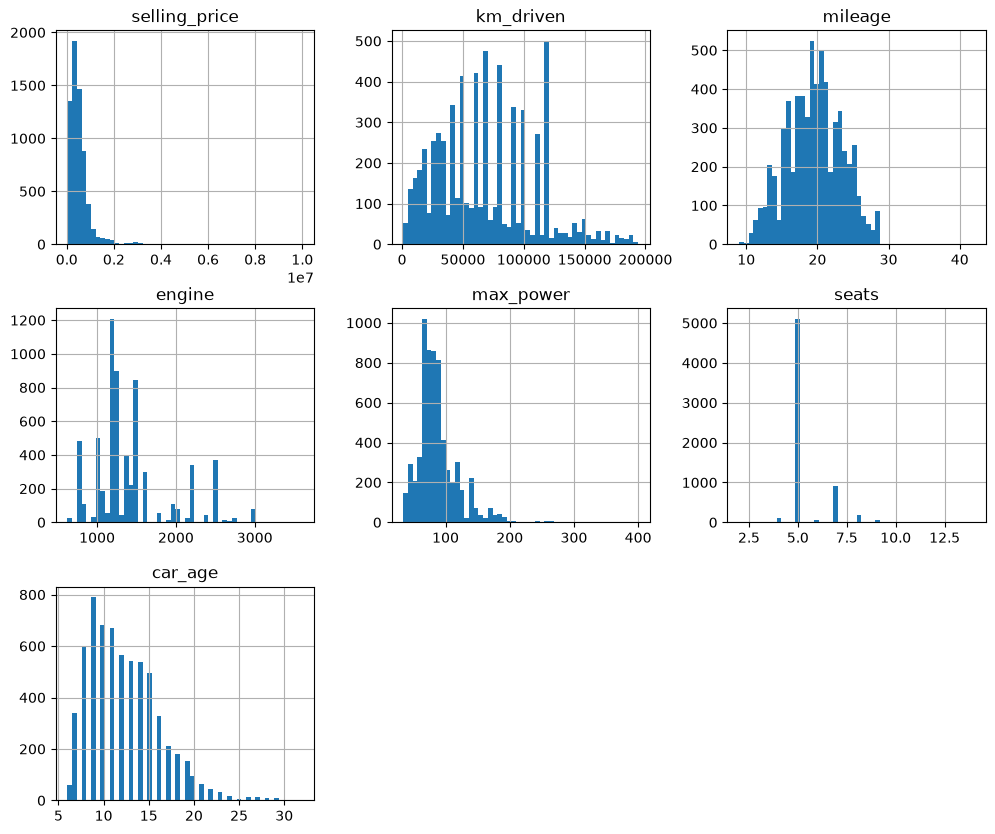

In [108]:
df.hist(bins=(50), figsize=(12, 10))

In [109]:
df.corr(numeric_only=True)["selling_price"].sort_values(ascending=False)

selling_price    1.000000
max_power        0.696767
engine           0.456828
seats            0.164362
mileage         -0.112815
km_driven       -0.219405
car_age         -0.428771
Name: selling_price, dtype: float64

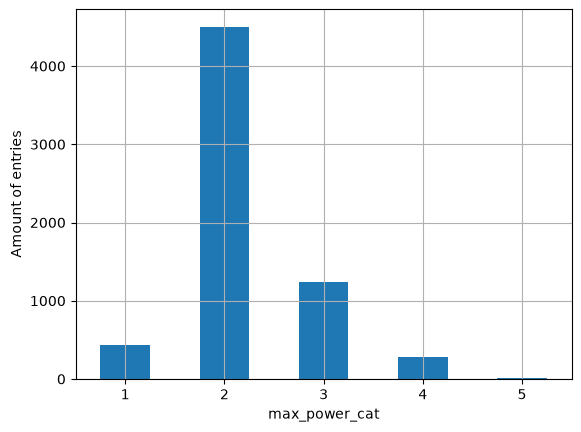

In [110]:
import matplotlib.pyplot as plt

df["max_power_cat"] = pd.cut(df["max_power"], bins=[0.0, 50.0, 100.0, 150.0, 250.0, np.inf], labels=[1, 2, 3, 4, 5])

cat_counts = df["max_power_cat"].value_counts().sort_index()
cat_counts.plot.bar(rot=0, grid=True)
plt.xlabel("max_power_cat")
plt.ylabel("Amount of entries")
plt.show()

In [111]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(df, test_size=0.2, stratify=df["max_power_cat"], random_state=42)
train_set = train_set.drop("max_power_cat", axis=1)
test_set = test_set.drop("max_power_cat", axis=1)

X_train, y_train = train_set.drop("selling_price", axis=1), train_set["selling_price"]

In [112]:
train_set.corr(numeric_only=True)['selling_price'].sort_values(ascending=False)

selling_price    1.000000
max_power        0.700005
engine           0.474268
seats            0.175407
mileage         -0.138147
km_driven       -0.225001
car_age         -0.440086
Name: selling_price, dtype: float64

In [113]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

owner_categories = ["Test Drive Car", "First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"]

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

owner_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(categories=[owner_categories])),
    ("scale", StandardScaler()),
])

num_attributes = ["max_power", "engine", "seats", "mileage", "km_driven", "car_age"]
cat_attributes = ["fuel", "seller_type", "transmission"]

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_attributes),
    ("cat", cat_pipeline, cat_attributes),
    ("owner", owner_pipeline, ["owner"]),
])

In [114]:
prep_data = preprocessing.fit_transform(df)
prep_df = pd.DataFrame(prep_data, columns=preprocessing.get_feature_names_out(), index=df.index)
prep_df

,num__max_power,num__engine,num__seats,num__mileage,num__km_driven,num__car_age,cat__fuel_Diesel,cat__fuel_Petrol,cat__seller_type_Dealer,cat__seller_type_Individual,cat__seller_type_Trustmark Dealer,cat__transmission_Automatic,cat__transmission_Manual,owner__owner
0,-0.439285,-0.359451,-0.430599,0.991292,1.928843,-0.077592,1.0,0.0,0.0,1.0,0.0,0.0,1.0,-0.670555
1,0.488547,0.157014,-0.430599,0.406366,1.288683,-0.077592,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.705411
2,-0.313563,0.154948,-0.430599,-0.483964,1.790769,1.986432,0.0,1.0,0.0,1.0,0.0,0.0,1.0,2.081376
3,0.063605,-0.053704,-0.430599,0.887765,1.464413,0.954420,1.0,0.0,0.0,1.0,0.0,0.0,1.0,-0.670555
4,0.007029,-0.256158,-0.430599,-0.898071,1.288683,1.728429,0.0,1.0,0.0,1.0,0.0,0.0,1.0,-0.670555
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6469,-0.656157,-0.875917,-0.430599,-0.173384,-0.468620,0.180411,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.705411
6470,0.023688,-0.053704,-0.430599,0.768709,0.284510,-0.077592,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.705411
6471,-0.161124,-0.464810,-0.430599,-0.276911,1.037639,0.180411,0.0,1.0,0.0,1.0,0.0,0.0,1.0,-0.670555
6472,0.692217,0.146684,-0.430599,-0.716899,1.263578,1.728429,1.0,0.0,0.0,1.0,0.0,0.0,1.0,3.457341


In [115]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold

cv = KFold(n_splits=10, shuffle=True, random_state=42)

def evaluate_rmses(model):
    s = -cross_val_score(model, X_train, y_train,
                            scoring='neg_root_mean_squared_error', cv=cv, n_jobs=-1)
    return s.mean(), s.std()

def evaluate_maes(model):
    s = -cross_val_score(model, X_train, y_train,
                            scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)
    return s.mean(), s.std()

In [116]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline

dummy_reg = DummyRegressor()
lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_log = TransformedTargetRegressor(lin_reg, func=np.log, inverse_func=np.exp)
forest_reg = make_pipeline(preprocessing, RandomForestRegressor(random_state=42))

print("RMSES")
print(evaluate_rmses(dummy_reg))
print(evaluate_rmses(lin_reg))
print(evaluate_rmses(lin_log))
print(evaluate_rmses(forest_reg))

print("MAES")
print(evaluate_maes(dummy_reg))
print(evaluate_maes(lin_reg))
print(evaluate_maes(lin_log))
print(evaluate_maes(forest_reg))

RMSES
(np.float64(518748.3678896686), np.float64(69527.90376643634))
(np.float64(311673.8606555265), np.float64(51127.30285985546))
(np.float64(214304.65177384616), np.float64(50923.077493507946))
(np.float64(161083.66118830998), np.float64(31423.72366972906))
MAES
(np.float64(298800.96256832604), np.float64(21804.002806898076))
(np.float64(176716.1362640191), np.float64(9464.456144733782))
(np.float64(113105.95706477326), np.float64(9948.462718191291))
(np.float64(80078.04714927093), np.float64(5015.159336389704))


In [117]:
forest = RandomForestRegressor(random_state=42)
forest.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [118]:
model = make_pipeline(preprocessing, RandomForestRegressor(random_state=42))

In [123]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

prefix = "randomforestregressor__"
param_distribs = {prefix + "n_estimators": (randint(low = 150, high = 200)),
                  prefix + "max_depth": [50, 100, None],
                  prefix + "max_features": (randint(low=3, high=15)),
                 }

rand_search = RandomizedSearchCV(model, param_distributions=param_distribs, n_iter=30, cv=cv,
                                 scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=42)
rand_search.fit(X_train, y_train)
print(rand_search.best_estimator_, -rand_search.best_score_)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['max_power', 'engine',
                                                   'seats', 'mileage',
                                                   'km_driven', 'car_age']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                    

In [124]:
pd.DataFrame(rand_search.cv_results_).head(3)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_randomforestregressor__max_depth,param_randomforestregressor__max_features,param_randomforestregressor__n_estimators,params,split0_test_score,split1_test_score,...,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,mean_test_score,std_test_score,rank_test_score
0,1.874138,0.067263,0.071493,0.013091,None,6,178,"{'randomforestregressor__max_depth': None, 'ra...",-173881.886159,-117951.376939,...,-104709.693634,-156094.010369,-133495.592702,-122716.103210,-215792.049492,-195507.650820,-169083.537355,-162804.511397,42088.676880,22
1,2.661104,0.212443,0.061702,0.015499,None,13,157,"{'randomforestregressor__max_depth': None, 'ra...",-180188.970720,-135899.994120,...,-115612.565471,-160471.554353,-128880.977104,-119935.218730,-212411.868554,-178387.835405,-175102.998492,-160696.757682,32321.614045,15
2,2.229631,0.161409,0.073670,0.009112,50,7,188,"{'randomforestregressor__max_depth': 50, 'rand...",-171570.143793,-117983.267200,...,-103964.240998,-151694.940034,-134429.611533,-122543.756595,-211769.849903,-191362.475292,-171104.751231,-159966.507087,38667.364412,13


In [125]:
from sklearn.metrics import root_mean_squared_error
final_model = rand_search.best_estimator_
X_test, y_test = test_set.drop("selling_price", axis=1), test_set["selling_price"]

predictions = final_model.predict(X_test)
print(root_mean_squared_error(y_test, predictions))

221752.56828524452


In [126]:
import joblib
joblib.dump(final_model, "my_used_car_price_forecasting_model.pkl")

['my_used_car_price_forecasting_model.pkl']